# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : KHAIRA MAULIDYA
- NIM   : 241011400201
- Kelas : Reg B/ ~~Reg C~~ *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 1 # isi dengan 2 digit terakhir NIM Anda

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Lima data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Ukuran dataset: (40, 2)
Jumlah baris data: 40

Bentuk X: (40, 1)
Bentuk y: (40,)


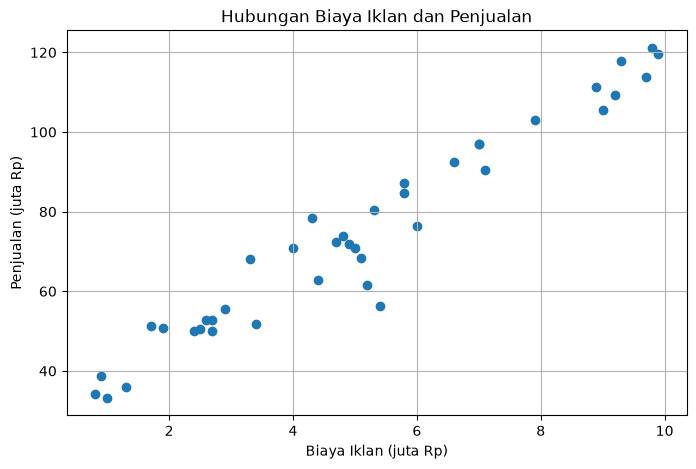

In [12]:
# Jawaban A1

# Membaca dataset biaya iklan dan penjualan
df = pd.read_csv("Ads_Data.csv")

# Menampilkan 5 data pertama
print("Lima data pertama:")
print(df.head())

# Menampilkan jumlah baris dan kolom
print("\nUkuran dataset:", df.shape)
print("Jumlah baris data:", len(df))

# Memisahkan variabel X dan y
X = df[["BiayaIklan"]].values
y = df["Penjualan"].values

# Memeriksa bentuk data
print("\nBentuk X:", X.shape)
print("Bentuk y:", y.shape)

# Membuat scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [13]:
# Jawaban A2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


In [14]:

# Fungsi membagi data menggunakan NumPy

def train_test_split(X, y, test_size=0.2, random_state=1):
    np.random.seed(random_state)

    indeks = np.random.permutation(len(X))
    jumlah_test = int(np.ceil(len(X) * test_size))

    indeks_test = indeks[:jumlah_test]
    indeks_train = indeks[jumlah_test:]

    return (
        X[indeks_train],
        X[indeks_test],
        y[indeks_train],
        y[indeks_test]
    )


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [15]:
# Jawaban A3

# Menambahkan kolom 1 untuk menghitung intercept
X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]

# Menghitung parameter model menggunakan Normal Equation
theta = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

# Mengambil intercept dan koefisien
b = theta[0]
m = theta[1]

print("Intercept (b):", b)
print("Koefisien (m):", m)
print(f"Persamaan regresi: y = {b:.4f} + {m:.4f}X")

Intercept (b): 29.89003065100048
Koefisien (m): 8.970670546165321
Persamaan regresi: y = 29.8900 + 8.9707X


**Jawaban A3 (interpretasi):** Nilai intercept sebesar 29,8900 menunjukkan bahwa ketika biaya iklan bernilai 0, penjualan diprediksi sebesar 29,89. Koefisien sebesar 8,9707 berarti setiap kenaikan biaya iklan sebesar 1 satuan akan meningkatkan penjualan yang diprediksi sebesar 8,9707 satuan. Dengan demikian, biaya iklan memiliki hubungan positif dengan penjualan, yaitu semakin besar biaya iklan, semakin tinggi penjualan yang diprediksi oleh model.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [16]:
# Jawaban A4

# Prediksi data training dan testing
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]

y_train_pred = X_train_b @ theta
y_test_pred = X_test_b @ theta

# Fungsi menghitung metrik evaluasi
def evaluasi_regresi(y_asli, y_pred):
    mae = np.mean(np.abs(y_asli - y_pred))
    mse = np.mean((y_asli - y_pred) ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum((y_asli - y_pred) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return mae, mse, rmse, r2

# Evaluasi training
mae_train, mse_train, rmse_train, r2_train = evaluasi_regresi(
    y_train, y_train_pred
)

# Evaluasi testing
mae_test, mse_test, rmse_test, r2_test = evaluasi_regresi(
    y_test, y_test_pred
)

print("=== Evaluasi Data Training ===")
print("MAE :", mae_train)
print("MSE :", mse_train)
print("RMSE:", rmse_train)
print("R2  :", r2_train)

print("\n=== Evaluasi Data Testing ===")
print("MAE :", mae_test)
print("MSE :", mse_test)
print("RMSE:", rmse_test)
print("R2  :", r2_test)

=== Evaluasi Data Training ===
MAE : 4.135486792861411
MSE : 33.15640944628301
RMSE: 5.758160248402523
R2  : 0.9446720848071667

=== Evaluasi Data Testing ===
MAE : 6.150252926282094
MSE : 52.9008561190404
RMSE: 7.273297472195153
R2  : 0.9314992967821704


**Jawaban A4 (analisis):** Berdasarkan hasil evaluasi, model Linear Regression memperoleh nilai MAE sebesar 4,14, MSE sebesar 33,16, RMSE sebesar 5,76, dan \(R^2\) sebesar 0,9447 pada data training. Pada data testing, diperoleh MAE sebesar 6,15, MSE sebesar 52,90, RMSE sebesar 7,27, dan \(R^2\) sebesar 0,9315. Nilai \(R^2\) yang mendekati 1 menunjukkan bahwa model mampu menjelaskan sebagian besar variasi data. Namun, kesalahan prediksi pada data testing lebih besar dibandingkan data training. Secara keseluruhan, model memiliki performa yang baik dalam memprediksi data, meskipun masih terdapat selisih antara nilai prediksi dan nilai sebenarnya.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Hasil Normal Equation A3
Intercept: 29.890030651000608
Koefisien: [8.97067055]

Learning rate: 0.001
Intercept: 29.888687166076863
Koefisien: [8.97026734]
Jumlah iterasi: 5000
Loss akhir: 33.1564218923677

Learning rate: 0.02
Intercept: 29.890030651000508
Koefisien: [8.97067055]
Jumlah iterasi: 5000
Loss akhir: 33.15640944628301

Learning rate: 0.1
Intercept: 29.890030651000586
Koefisien: [8.97067055]
Jumlah iterasi: 5000
Loss akhir: 33.15640944628302


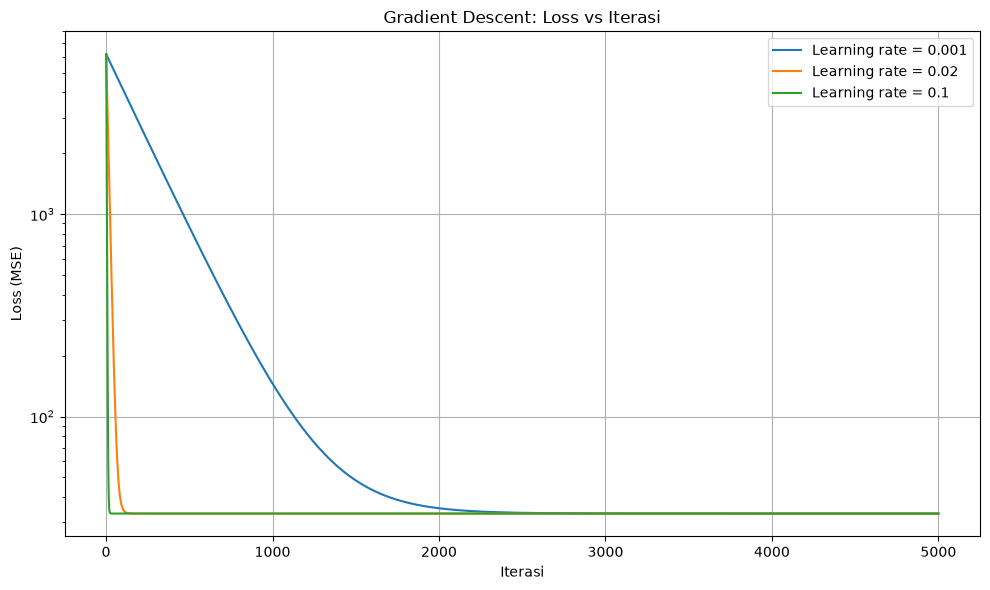

In [19]:

# Jawaban A5

# Class LinearRegressionGD
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        y = np.asarray(y, dtype=float).ravel()

        # Normalisasi fitur
        self.X_mean = np.mean(X, axis=0)
        self.X_std = np.std(X, axis=0)
        self.X_std[self.X_std == 0] = 1

        X_scaled = (X - self.X_mean) / self.X_std

        # Menambahkan intercept
        X_b = np.c_[np.ones(len(X_scaled)), X_scaled]
        self.theta = np.zeros(X_b.shape[1])
        self.loss_history = []

        for _ in range(self.n_iterations):
            error = X_b @ self.theta - y
            loss = np.mean(error ** 2)

            if not np.isfinite(loss):
                break

            self.loss_history.append(loss)

            gradients = (2 / len(y)) * (X_b.T @ error)
            self.theta -= self.learning_rate * gradients

            if not np.all(np.isfinite(self.theta)):
                break

        # Mengembalikan parameter ke skala fitur asli
        self.coef_ = self.theta[1:] / self.X_std
        self.intercept_ = (
            self.theta[0] - np.sum(self.coef_ * self.X_mean)
        )

        return self


# Normal Equation sebagai pembanding A3
X_train_2d = np.asarray(X_train, dtype=float)

if X_train_2d.ndim == 1:
    X_train_2d = X_train_2d.reshape(-1, 1)

y_train_array = np.asarray(y_train, dtype=float).ravel()

X_train_b = np.c_[np.ones(len(X_train_2d)), X_train_2d]
theta_normal = np.linalg.pinv(X_train_b) @ y_train_array

print("Hasil Normal Equation A3")
print("Intercept:", theta_normal[0])
print("Koefisien:", theta_normal[1:])

# Eksperimen tiga learning rate
learning_rates = [0.001, 0.02, 0.1]
results = {}

for lr in learning_rates:
    model = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )
    model.fit(X_train, y_train)
    results[lr] = model

    print(f"\nLearning rate: {lr}")
    print("Intercept:", model.intercept_)
    print("Koefisien:", model.coef_)
    print("Jumlah iterasi:", len(model.loss_history))

    if model.loss_history:
        print("Loss akhir:", model.loss_history[-1])
    else:
        print("Loss akhir: tidak tersedia")

# Grafik Loss vs Iterasi
plt.figure(figsize=(10, 6))

for lr, model in results.items():
    losses = np.asarray(model.loss_history)

    if len(losses) > 0:
        plt.plot(
            range(1, len(losses) + 1),
            losses,
            label=f"Learning rate = {lr}"
        )

plt.xlabel("Iterasi")
plt.ylabel("Loss (MSE)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**  Learning rate 0.001 memiliki proses pembelajaran yang relatif lambat karena perubahan parameter pada setiap iterasi kecil. Learning rate 0.02 dapat menghasilkan konvergensi yang lebih cepat dan stabil jika nilai loss terus menurun. Sementara itu, learning rate 0.1 memiliki langkah pembaruan yang lebih besar sehingga berpotensi menyebabkan divergensi apabila nilai loss meningkat tidak terkendali. Jika muncul RuntimeWarning: overflow, artinya nilai perhitungan menjadi terlalu besar sehingga menghasilkan nilai loss inf. Hal ini dapat terjadi karena learning rate terlalu besar untuk skala data yang digunakan. Hasil Gradient Descent dibandingkan dengan Normal Equation A3 untuk mengetahui apakah intercept dan koefisien yang diperoleh mendekati nilai optimal.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

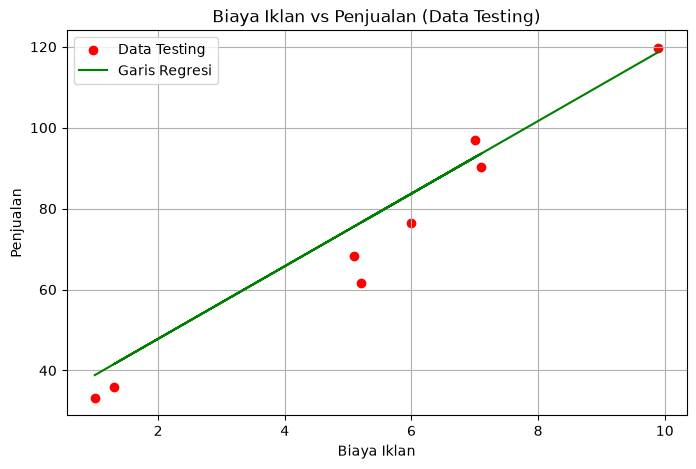

Biaya iklan 4.5 juta: prediksi penjualan = 70.2580
Biaya iklan 7.0 juta: prediksi penjualan = 92.6847
Biaya iklan 12.0 juta: prediksi penjualan = 137.5381


In [ ]:
# Jawaban A6


# Menyiapkan data
X_train_2d = np.asarray(X_train).reshape(-1, 1)
X_test_2d = np.asarray(X_test).reshape(-1, 1)

# Melatih model Linear Regression sesuai A3
regressor = LinearRegression()
regressor.fit(X_train_2d, y_train)

# 1. Grafik scatter data testing dan garis regresi
y_test_pred = regressor.predict(X_test_2d)

plt.figure(figsize=(8, 5))
plt.scatter(X_test_2d, y_test, color="red", label="Data Testing")
plt.plot(
    X_test_2d.ravel(),
    y_test_pred,
    color="green",
    label="Garis Regresi"
)
plt.title("Biaya Iklan vs Penjualan (Data Testing)")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True)
plt.show()

# 2. Prediksi penjualan
biaya_iklan = np.array([[4.5], [7], [12]])
prediksi = regressor.predict(biaya_iklan)

for biaya, hasil in zip(biaya_iklan.ravel(), prediksi):
    print(f"Biaya iklan {biaya} juta: prediksi penjualan = {hasil:.4f}")


**Jawaban A6 (analisis):**

Prediksi penjualan menggunakan regresi linear dilakukan dengan memasukkan nilai biaya iklan ke dalam persamaan regresi yang diperoleh pada Soal A3. Prediksi untuk biaya iklan Rp4,5 juta, Rp7 juta, dan Rp12 juta dihitung menggunakan model yang sama. Prediksi Rp12 juta kurang dapat dipercaya apabila berada di luar rentang data training, karena model belum tentu menggambarkan hubungan biaya iklan dan penjualan pada nilai tersebut. Oleh karena itu, hasil ekstrapolasi perlu digunakan dengan hati-hati dan sebaiknya didukung data tambahan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Lima data pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah email Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64

Fitur X:
   JumlahLink  KataPromo
0           0          0
1           2          4
2           6          7
3          10          8
4           8          7

Target y:
0    0
1    0
2    1
3    1
4    1
Name: Spam, dtype: int64


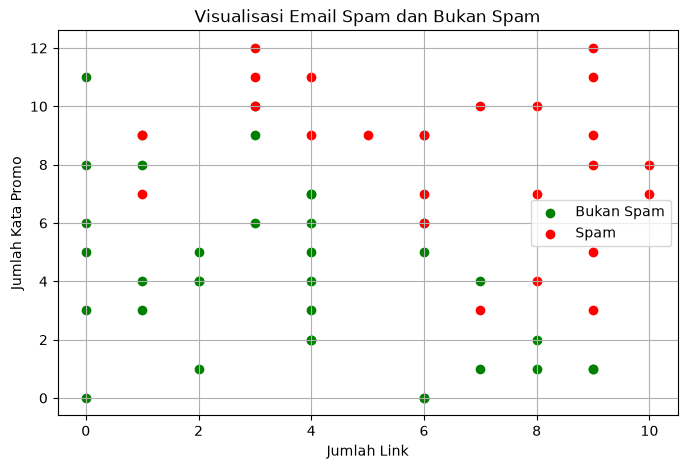

In [ ]:
# Jawaban B1


# 1. Membaca dataset
df_email = pd.read_csv("Email_Data.csv")

# Menampilkan 5 data pertama
print("Lima data pertama:")
print(df_email.head())

# Menghitung jumlah Spam dan Bukan Spam
print("\nJumlah email Spam dan Bukan Spam:")
print(df_email["Spam"].value_counts())

# 2. Memisahkan fitur X dan target y
X = df_email[["JumlahLink", "KataPromo"]]
y = df_email["Spam"]

print("\nFitur X:")
print(X.head())

print("\nTarget y:")
print(y.head())

# 3. Scatter plot Spam dan Bukan Spam
spam = df_email[df_email["Spam"] == 1]
bukan_spam = df_email[df_email["Spam"] == 0]

plt.figure(figsize=(8, 5))

plt.scatter(
    bukan_spam["JumlahLink"],
    bukan_spam["KataPromo"],
    color="green",
    label="Bukan Spam"
)

plt.scatter(
    spam["JumlahLink"],
    spam["KataPromo"],
    color="red",
    label="Spam"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Visualisasi Email Spam dan Bukan Spam")
plt.legend()
plt.grid(True)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Jumlah data training: 45
Jumlah data testing: 15

Intercept (b): -9.74209133125333
Koefisien m1 (JumlahLink): 0.9208419041152044
Koefisien m2 (KataPromo): 0.7431002073462643

Persamaan model:
P(Spam) = sigmoid(-9.7421 + (0.9208 * JumlahLink) + (0.7431 * KataPromo))


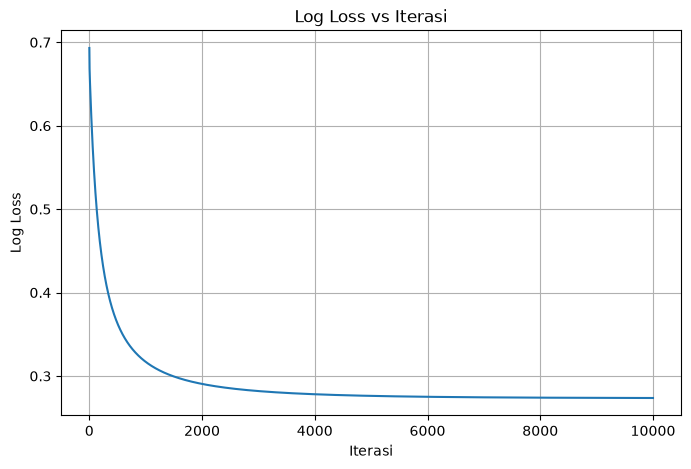

Loss awal: 0.6931471805599452
Loss akhir: 0.2736336637485847


In [ ]:
# Jawaban B2


# 1. Load data dan pisahkan fitur dengan target
df = pd.read_csv("Email_Data.csv")

X = df[["JumlahLink", "KataPromo"]].values
y = df["Spam"].values

# Pastikan target berupa angka 0 dan 1
# 0 = Bukan Spam, 1 = Spam
if y.dtype == object:
    y = np.where(y == "Spam", 1, 0)

# Samakan bentuk target menjadi array 1 dimensi
y = y.astype(float).reshape(-1)

RANDOM_STATE = 42

# 2. Split data: 75% training dan 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# 3. Fungsi sigmoid
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# 4. Inisialisasi parameter
learning_rate = 0.1
n_iterations = 10000

b = 0.0
m = np.zeros(X_train.shape[1])
loss_history = []

# 5. Training dengan Gradient Descent
for i in range(n_iterations):
    z = b + X_train @ m
    p = sigmoid(z)

    # Hitung log loss
    eps = 1e-15
    p_safe = np.clip(p, eps, 1 - eps)
    loss = -np.mean(
        y_train * np.log(p_safe)
        + (1 - y_train) * np.log(1 - p_safe)
    )
    loss_history.append(loss)

    # Hitung gradien
    error = p - y_train
    db = np.mean(error)
    dm = X_train.T @ error / len(y_train)

    # Update parameter
    b -= learning_rate * db
    m -= learning_rate * dm

# 6. Tampilkan intercept dan koefisien
print("\nIntercept (b):", b)
print("Koefisien m1 (JumlahLink):", m[0])
print("Koefisien m2 (KataPromo):", m[1])

print("\nPersamaan model:")
print(
    f"P(Spam) = sigmoid({b:.4f} "
    f"+ ({m[0]:.4f} * JumlahLink) "
    f"+ ({m[1]:.4f} * KataPromo))"
)

# 7. Grafik Log Loss vs Iterasi
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_iterations + 1), loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss vs Iterasi")
plt.grid(True)
plt.show()

print("Loss awal:", loss_history[0])
print("Loss akhir:", loss_history[-1])


**Jawaban B2 (analisis):**

Data dibagi menjadi 75% data training dan 25% data testing menggunakan train_test_split dengan random_state=42. Model Logistic Regression dilatih menggunakan metode gradient descent dengan learning rate 0,1 dan 10.000 iterasi. Nilai intercept dan koefisien digunakan untuk membentuk persamaan probabilitas spam. Grafik log loss digunakan untuk melihat proses pembelajaran model. Jika loss menurun lalu cenderung mendatar, berarti model belajar dan mulai mencapai kondisi stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3


# 1. Prediksi data testing
y_prob = sigmoid(b + X_test @ m)
y_pred = (y_prob >= 0.5).astype(int)

# 2. Hitung accuracy
accuracy = accuracy_score(y_test, y_pred)

# 3. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
TN, FP, FN, TP = cm.ravel()

# 4. Implementasi manual Precision, Recall, dan F1
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# 5. Tampilkan hasil
print("Accuracy:", accuracy)
print("\nConfusion Matrix:")
print(cm)

print("\nTN (Bukan Spam diprediksi Bukan Spam):", TN)
print("FP (Bukan Spam diprediksi Spam):", FP)
print("FN (Spam diprediksi Bukan Spam):", FN)
print("TP (Spam diprediksi Spam):", TP)

print("\nPrecision:", precision)
print("Recall:", recall)
print("F1-score:", f1)


Accuracy: 0.9333333333333333

Confusion Matrix:
[[9 0]
 [1 5]]

TN (Bukan Spam diprediksi Bukan Spam): 9
FP (Bukan Spam diprediksi Spam): 0
FN (Spam diprediksi Bukan Spam): 1
TP (Spam diprediksi Spam): 5

Precision: 1.0
Recall: 0.8333333333333334
F1-score: 0.9090909090909091


**Jawaban B3 (analisis):** FP (False Positive) adalah kesalahan ketika email yang sebenarnya bukan spam justru dianggap sebagai spam. Akibatnya, email penting dapat masuk ke folder spam. FN (False Negative) adalah kesalahan ketika email spam dianggap sebagai email biasa sehingga dapat masuk ke kotak masuk pengguna.
Menurut saya, FP dapat lebih merugikan pengguna apabila email penting, seperti informasi kuliah atau pekerjaan, tidak terbaca karena masuk ke folder spam. Namun, FN juga berbahaya karena pesan spam dapat berisi penipuan atau tautan berbahaya. Oleh karena itu, model filter spam harus memiliki precision dan recall yang baik agar dapat mengurangi kedua jenis kesalahan tersebut.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan decision boundary:
x2 = -(-9.7421 + (0.9208 * x1)) / (0.7431)


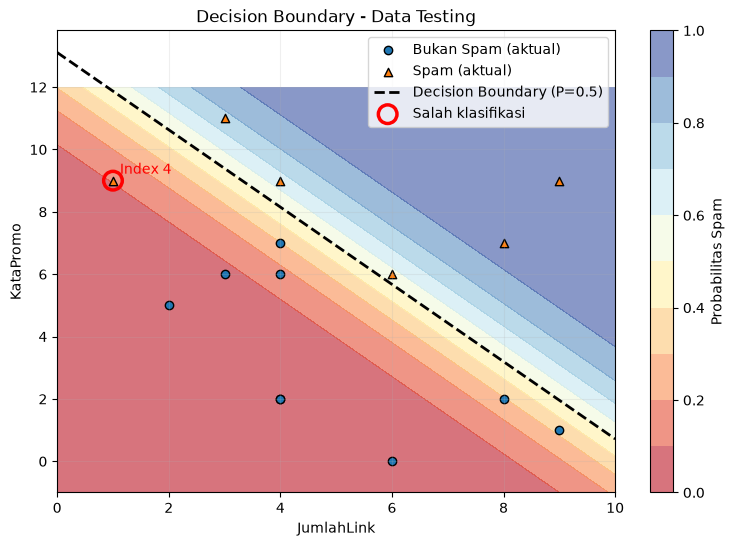

Jumlah data salah klasifikasi: 1

Detail data yang salah diklasifikasikan:
Index testing 4: JumlahLink=1, KataPromo=9, Aktual=1, Prediksi=0


In [27]:
# Jawaban B4

# 1. Persamaan decision boundary
print("Persamaan decision boundary:")

if abs(m[1]) > 1e-12:
    print(
        f"x2 = -({b:.4f} + ({m[0]:.4f} * x1))"
        f" / ({m[1]:.4f})"
    )
else:
    print("Decision boundary berupa garis vertikal.")

# 2. Buat area untuk background probabilitas
x1_min, x1_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
x2_min, x2_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

# Hitung probabilitas spam pada setiap titik
grid = np.c_[xx1.ravel(), xx2.ravel()]
Z = sigmoid(b + grid @ m).reshape(xx1.shape)

# 3. Visualisasi background dan data testing
plt.figure(figsize=(9, 6))

contour = plt.contourf(
    xx1, xx2, Z,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu",
    alpha=0.6
)

plt.colorbar(contour, label="Probabilitas Spam")

# Data testing sebenarnya
plt.scatter(
    X_test[y_test == 0, 0],
    X_test[y_test == 0, 1],
    marker="o", edgecolors="black",
    label="Bukan Spam (aktual)"
)

plt.scatter(
    X_test[y_test == 1, 0],
    X_test[y_test == 1, 1],
    marker="^", edgecolors="black",
    label="Spam (aktual)"
)

# 4. Garis decision boundary: probabilitas = 0.5
if abs(m[1]) > 1e-12:
    x1_line = np.linspace(x1_min, x1_max, 200)
    x2_line = -(b + m[0] * x1_line) / m[1]

    plt.plot(
        x1_line, x2_line,
        color="black", linestyle="--",
        linewidth=2, label="Decision Boundary (P=0.5)"
    )
else:
    x1_boundary = -b / m[0]
    plt.axvline(
        x1_boundary,
        color="black", linestyle="--",
        linewidth=2, label="Decision Boundary (P=0.5)"
    )

# 5. Tandai data testing yang salah diklasifikasikan
wrong = y_test != y_pred

plt.scatter(
    X_test[wrong, 0],
    X_test[wrong, 1],
    s=180, facecolors="none",
    edgecolors="red", linewidths=2.5,
    label="Salah klasifikasi"
)

# Beri nomor pada setiap titik yang salah
for i in np.where(wrong)[0]:
    plt.annotate(
        f"Index {i}",
        (X_test[i, 0], X_test[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        color="red"
    )

plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.title("Decision Boundary - Data Testing")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# 6. Tampilkan data yang salah diklasifikasikan
print("Jumlah data salah klasifikasi:", wrong.sum())

print("\nDetail data yang salah diklasifikasikan:")
for i in np.where(wrong)[0]:
    print(
        f"Index testing {i}: "
        f"JumlahLink={X_test[i, 0]}, "
        f"KataPromo={X_test[i, 1]}, "
        f"Aktual={int(y_test[i])}, "
        f"Prediksi={int(y_pred[i])}"
    )


**Jawaban B4 (analisis):** Decision boundary merupakan garis pemisah antara kelas spam dan bukan spam dengan probabilitas sebesar 0,5. Persamaannya diperoleh dari b+m1x1+m2x2=0, sehingga x2=-(b+m1x1)/m_2. Grafik menampilkan data testing, latar belakang probabilitas, dan garis batas klasifikasi. Data yang dilingkari merah merupakan data yang salah diprediksi oleh model. Kesalahan tersebut dapat terjadi karena karakteristik email spam dan bukan spam memiliki kemiripan.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [26]:
# Jawaban B5


# Probabilitas prediksi dari model B2
# Karena model B2 dibuat manual dengan gradient descent,
# probabilitas dihitung menggunakan sigmoid.
y_prob = sigmoid(b + X_test @ m)

thresholds = [0.3, 0.5, 0.7]
results = []

for threshold in thresholds:
    # Prediksi spam berdasarkan threshold
    y_pred_threshold = (y_prob >= threshold).astype(int)

    # Confusion matrix: TN, FP, FN, TP
    cm = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    )
    TN, FP, FN, TP = cm.ravel()

    # Precision
    precision = (
        TP / (TP + FP) if (TP + FP) > 0 else 0
    )

    # Recall
    recall = (
        TP / (TP + FN) if (TP + FN) > 0 else 0
    )

    results.append({
        "Threshold": threshold,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "Precision": precision,
        "Recall": recall
    })

# Tampilkan semua hasil dalam satu tabel
tabel_b5 = pd.DataFrame(results)

print(tabel_b5.round(4).to_string(index=False))


 Threshold  TN  FP  FN  TP  Precision  Recall
       0.3   8   1   1   5     0.8333  0.8333
       0.5   9   0   1   5     1.0000  0.8333
       0.7   9   0   3   3     1.0000  0.5000


**Jawaban B5 (analisis):** Menurunkan threshold dari 0,5 menjadi 0,3 membuat model lebih mudah mengklasifikasikan email sebagai spam. Hal ini biasanya meningkatkan recall, tetapi juga dapat meningkatkan false positive sehingga email penting salah masuk ke folder spam. Sebaliknya, menaikkan threshold menjadi 0,7 membuat model lebih ketat dalam mendeteksi spam sehingga precision biasanya meningkat, tetapi recall dapat menurun karena lebih banyak email spam tidak terdeteksi.
Menurut saya, threshold yang dipilih harus mempertimbangkan hasil precision dan recall pada Soal B3. Untuk filter spam, saya akan memilih threshold 0,3 jika prioritasnya mendeteksi sebanyak mungkin email spam. Namun, jika ingin mengurangi risiko email penting masuk ke folder spam, threshold 0,7 dapat dipertimbangkan. Pilihan akhir sebaiknya didasarkan pada hasil tabel pengujian.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [25]:
# Jawaban B6

# Threshold pilihan dari B5
threshold = 0.5

# Data email baru
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

# Ambil fitur email
X_baru = email_baru[["JumlahLink", "KataPromo"]].values

# Hitung probabilitas Spam menggunakan model B2
prob_spam = sigmoid(b + X_baru @ m)

# Tentukan kelas berdasarkan threshold
prediksi = (prob_spam >= threshold).astype(int)

# Susun hasil
hasil_b6 = email_baru.copy()
hasil_b6["Probabilitas Spam"] = prob_spam
hasil_b6["Prediksi"] = np.where(
    prediksi == 1, "Spam", "Bukan Spam"
)

print("Threshold yang digunakan:", threshold)
print(hasil_b6.round(4).to_string(index=False))


Threshold yang digunakan: 0.5
Email  JumlahLink  KataPromo  Probabilitas Spam   Prediksi
   E1           1          2             0.0007 Bukan Spam
   E2           5          6             0.3364 Bukan Spam
   E3           9         10             0.9975       Spam
   E4           2         11             0.5680       Spam


**Jawaban analisis B6 :**
Prediksi email baru dilakukan menggunakan model Logistic Regression yang telah dilatih pada Soal B2. Model menghitung probabilitas spam berdasarkan jumlah link dan jumlah kata promosi. Selanjutnya, probabilitas dibandingkan dengan threshold yang dipilih pada Soal B5 untuk menentukan kelas email. Email dengan probabilitas yang mencapai atau melebihi threshold dikategorikan sebagai spam, sedangkan email dengan probabilitas di bawah threshold dikategorikan sebagai bukan spam.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** = Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kelas, misalnya email spam atau bukan spam. Walaupun namanya mengandung kata regression, hasil akhirnya berupa kategori berdasarkan probabilitas. Fungsi sigmoid mengubah nilai perhitungan menjadi probabilitas antara 0 dan 1. Probabilitas tersebut digunakan untuk menentukan kelas berdasarkan threshold.

**Jawaban C2:** = Normal Equation menghitung nilai koefisien secara langsung menggunakan rumus matematika tanpa proses iterasi. Sementara itu, Gradient Descent mencari koefisien secara bertahap dengan memperbarui nilai parameter agar kesalahan semakin kecil. Normal Equation cocok untuk dataset yang relatif kecil dan perhitungannya memungkinkan dilakukan secara langsung. Gradient Descent lebih cocok untuk dataset besar karena dapat memperbarui parameter secara bertahap.

**Jawaban C3:** = Data testing digunakan untuk mengetahui kemampuan model dalam memprediksi data baru yang belum pernah dipelajari. Jika evaluasi hanya menggunakan data training, hasilnya bisa terlihat bagus tetapi belum tentu akurat pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga kurang mampu memprediksi data baru. Oleh karena itu, data testing penting untuk mengukur kemampuan generalisasi model.

**Jawaban C4:** = Linear Regression menggunakan Mean Squared Error (MSE) untuk menghitung rata-rata kuadrat selisih antara nilai prediksi dan nilai sebenarnya. Logistic Regression menggunakan log loss karena menghasilkan probabilitas untuk kelas tertentu. Log loss memberikan penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi prediksinya salah. Kedua fungsi loss tersebut digunakan untuk mengukur kesalahan sesuai dengan jenis keluaran model.

**Jawaban C5:** = Hasil perhitungan dapat berbeda karena pembagian data training dan testing menggunakan nilai random_state yang berbeda. Selain itu, nilai awal parameter, learning rate, jumlah iterasi, dan proses optimasi juga dapat memengaruhi hasil. Perbedaan pengolahan data atau parameter model juga bisa menghasilkan koefisien dan akurasi yang berbeda. Oleh karena itu, pengaturan eksperimen harus dibuat sama agar hasilnya dapat dibandingkan secara adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [4]:
# Jawaban Bonus

# ======================================
# A. LINEAR REGRESSION - Ads_Data.csv
# ======================================
ads = pd.read_csv("Ads_Data.csv")

print("Kolom Ads_Data:", ads.columns.tolist())

# Sesuaikan nama kolom jika berbeda
X_ads = ads[["BiayaIklan"]]
y_ads = ads["Penjualan"]

X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.25,
    random_state=RANDOM_STATE
)

# Model scikit-learn
linear_sklearn = LinearRegression()
linear_sklearn.fit(X_train_ads, y_train_ads)

pred_linear = linear_sklearn.predict(X_test_ads)

print("\n=== LINEAR REGRESSION ===")
print("Intercept:", linear_sklearn.intercept_)
print("Koefisien:", linear_sklearn.coef_)
print("MSE testing:", mean_squared_error(y_test_ads, pred_linear))
print("R2 testing:", r2_score(y_test_ads, pred_linear))

# ======================================
# B. LOGISTIC REGRESSION - Email_Data.csv
# ======================================
email = pd.read_csv("Email_Data.csv")

X_email = email[["JumlahLink", "KataPromo"]]
y_email = email["Spam"]

# Jika label berupa teks
if y_email.dtype == object:
    y_email = y_email.map({
        "Bukan Spam": 0,
        "Spam": 1
    })

X_train_email, X_test_email, y_train_email, y_test_email = (
    train_test_split(
        X_email, y_email,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=y_email
    )
)

# Model scikit-learn dengan regularisasi default
log_sklearn = LogisticRegression(max_iter=10000)
log_sklearn.fit(X_train_email, y_train_email)

pred_log = log_sklearn.predict(X_test_email)

print("\n=== LOGISTIC REGRESSION ===")
print("Intercept:", log_sklearn.intercept_[0])
print("Koefisien:", log_sklearn.coef_[0])
print("Accuracy testing:", accuracy_score(y_test_email, pred_log))

# Bandingkan dengan model manual B2
print("\n=== PERBANDINGAN KOEFISIEN LOGISTIC ===")
print("Intercept sklearn:", log_sklearn.intercept_[0])
print("Koefisien sklearn:", log_sklearn.coef_[0])


Kolom Ads_Data: ['BiayaIklan', 'Penjualan']

=== LINEAR REGRESSION ===
Intercept: 29.874372966140832
Koefisien: [8.95009275]
MSE testing: 44.92310925992679
R2 testing: 0.9294708651625154

=== LOGISTIC REGRESSION ===
Intercept: -8.70610899302471
Koefisien: [0.73188427 0.76437206]
Accuracy testing: 0.9333333333333333

=== PERBANDINGAN KOEFISIEN LOGISTIC ===
Intercept sklearn: -8.70610899302471
Koefisien sklearn: [0.73188427 0.76437206]


**Jawaban Bonus (analisis):** Berdasarkan hasil pengujian, model Linear Regression memperoleh intercept sebesar 29,8743 dan koefisien sebesar 8,9501. Nilai MSE testing sebesar 44,9231 dan R^2 sebesar 0,9295 menunjukkan bahwa model mampu menjelaskan sekitar 92,95% variasi penjualan pada data testing. Sementara itu, model Logistic Regression memperoleh akurasi sebesar 93,33% pada data testing. Model ini memiliki intercept sebesar -8,7061 dan koefisien sebesar 0,7319 serta 0,7644. Perbedaan koefisien Logistic Regression dari model manual dapat terjadi karena proses optimasi dan metode perhitungan yang digunakan. Secara keseluruhan, kedua model memiliki fungsi berbeda: Linear Regression digunakan untuk memprediksi nilai penjualan, sedangkan Logistic Regression digunakan untuk klasifikasi.